# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [83]:
STUDENT_NAME = 'Паничевська Ярина Ернестівна'
LIST_NUMBER  = 15

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 15, файл lr6_варіант_15.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [84]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [85]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [86]:
TYPE_OF_TASK = 'класифікація'

METRIC = 'AUC'

CV_SCHEME = 'стратифікована 5 кратна, з 4 повторами'

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


In [87]:
data = pd.read_csv(os.path.join(path='╨┤╨░╨╜╤û\lr6_╨▓╨░╤Ç╤û╨░╨╜╤é_15.csv'), encoding='utf-8-sig')
print(data['відтік'].value_counts())

відтік
0    886
1    314
Name: count, dtype: int64


**Тип задачі** Класифікація, оскільки, у завданні просять оцінити чи клієнт **розірве** чи **не розірве** контракт. По-суті, маємо два класи і на мна основі ознак клєнта треба віднести до якого класу він належить. Також на це вкахує колонка `відтік`, яка має два числа 0 та 1.

**Метрика** AUC, тому що, по-перше, у нас присутній дисбаланс класів: к-сть клієнтів з відтоком `0` - 886 (~74%), з відтоком `1` - 314 (~26%) і, по-друге, не залежить від порогу.

    Точність (accuracy) тут однозначно не підійде, бо модель буде завищувати оцінку через дизбаланс класів. 

    MAE - метрика для задач регресії. 

    F1 - рахується при конкретному порозі (наприклад, «ризик > 0,5 означає, що клієнт піде»). А поріг у нашій задачі вирішує бізнес. На етапі вибору моделі ми цього не знаємо.

    Повнота (recall) -  враховує лише клієнтів, які реально пішли, і не карає модель за хибні тривоги. Модель, яка всіх клієнтів позначає як ризикових, отримає повноту `1.0`, хоча нічого не розрізняє. Оскільки за підказкою моделі відділ утримання обдзвонюватиме ризикових клієнтів і пропонуватиме знижку, така модель призвела б до того, що знижку отримали б усі, зокрема ~74 % клієнтів, які й так не збиралися йти.

**Схема крос-валідації — стратифікована 5-кратна з 4 повторами.**

- **Стратифікована**, бо класи незбалансовані: без стратифікації частка відтоку в згортках могла б помітно відрізнятись, і оцінки на них були б непорівнянні.
- **5 згорток** — баланс між розміром тестової і навчальної частин
- **4 повтори**, бо одна перевірка залежить від випадкового перемішування. Повтори усереднюють цей вплив і дають 20 оцінок замість 5. Більше повторів -> час росте навчання росте.

> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [88]:
TARGET = 'відтік'

print('розмір:', data.shape)
print('частка відтоку: %.3f' % data[TARGET].mean())
print()
print('типи стовпців:', data.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.262

типи стовпців: {'object': 13, 'float64': 7, 'int64': 6}


In [89]:
overview = pd.DataFrame({
    'тип': data.dtypes.astype(str),
    'унікальних': data.nunique(),
    '% пропусків': (data.isna().mean() * 100).round(1),
}).sort_values('% пропусків', ascending=False)
overview.index.name = 'стовпець'
display(overview)

,тип,унікальних,% пропусків
стовпець,,,
сума_повернення_депозиту,float64,313,73.8
дата_розірвання,object,257,73.8
середній_час_відповіді_хв,float64,273,34.6
трафік_ГБ,object,951,5.0
щомісячний_платіж,object,1127,4.0
аварій_на_ділянці_за_квартал,float64,5,3.0
id_клієнта,object,1200,0.0
кількість_дзвінків_утримання,int64,6,0.0
дата_підключення,object,587,0.0


**Кількість рядків, стовпців** 1200, 26

**Частка відтоку** 0.262

**Кількість стовпців, які мають невизначений тип** 13

**У якому стовпці найбільше пропусків** `сума_повернення_депозиту` (74%), `дата_розірвання` (74%)

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [90]:
data

,id_клієнта,вік,стать,місто,філія,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,трафік_МБ,номер_договору_серія,скоринг_партнера,дата_підключення,дата_розірвання,сума_повернення_депозиту,кількість_дзвінків_утримання,відтік
0,K150000,18.0,жін,Львів,Ф-02 Захід,Оптимальний,оптика,картка,так,3,76.0,200,271.94,10,282.8,1,0.0,12.1,289194.4,НОМ-027,428.914,2024-08-14,NaN,NaN,0,0
1,K150001,29.0,ч,Червоноград,Ф-04 Південь,Базовий,ADSL,картка,так,3,23.0,100,326.64,0,147.3,1,0.0,2.0,153297.7,НОМ-002,60.927,2023-07-10,NaN,NaN,0,0
2,K150002,45.0,жін,Львів,Ф-04 Південь,Максимальний,оптика,термінал,ні,3,29.0,100,344.23,20,133.4,3,0.0,4.0,137192.7,НОМ-005,531.688,2023-03-03,NaN,NaN,0,0
3,K150003,57.0,ж,Львів,Ф-05 Північ,Оптимальний,ADSL,картка,так,2,19.0,1000,458.19,0,170.4,4,0.0,7.7,174515.3,НОМ-017,97.954,2024-10-31,2025-09-27,416.00,3,1
4,K150004,38.0,ч,Львів,Ф-05 Північ,Оптимальний,ADSL,картка,ні,3,17.0,50,281.73,0,261.6,3,1.0,5.3,266509.0,НОМ-029,132.764,2023-06-03,NaN,NaN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,K151195,23.0,ч,Львів,Ф-03 Схід,Бізнес,оптика,картка,ні,2,11.0,100,273.65,10,122.5,0,0.0,NaN,125466.8,НОМ-021,981.348,2024-02-06,NaN,NaN,0,0
1196,K151196,48.0,Ж,Червоноград,Ф-02 Захід,Базовий,оптика,картка,ні,1,31.0,50,163.57,10,182.1,2,1.0,12.7,191800.8,НОМ-003,461.154,2023-01-15,NaN,NaN,0,0
1197,K151197,28.0,Ч,Львів,Ф-03 Схід,Базовий,оптика,термінал,ні,2,7.0,100,251.12,10,148.8,2,4.0,6.6,152508.8,НОМ-050,601.423,2023-07-25,2024-04-05,252.63,3,1
1198,K151198,53.0,Ж,Червоноград,Ф-02 Захід,Оптимальний,оптика,картка,так,3,18.0,400,380.88,0,265.9,1,1.0,15.2,271069.3,НОМ-047,899.960,2024-11-28,NaN,NaN,0,0


In [91]:
display(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_клієнта                      1200 non-null   object 
 1   вік                             1200 non-null   float64
 2   стать                           1200 non-null   object 
 3   місто                           1200 non-null   object 
 4   філія                           1200 non-null   object 
 5   тариф                           1200 non-null   object 
 6   тип_підключення                 1200 non-null   object 
 7   спосіб_оплати                   1200 non-null   object 
 8   автоплатіж                      1200 non-null   object 
 9   кількість_послуг                1200 non-null   int64  
 10  місяців_обслуговування          1200 non-null   float64
 11  швидкість_тарифу_Мбіт           1200 non-null   int64  
 12  щомісячний_платіж               11

None

In [92]:
text_in_number_examples = []

for _, v in data['щомісячний_платіж'].items():
    try:
        float(v)      
    except ValueError:
        text_in_number_examples.append(v)

print('знайдено:', len(text_in_number_examples))
print(text_in_number_examples[:10])

знайдено: 27
['373.35 грн', '253.3 грн', '506.57 грн', '355.37 грн', '368.58 грн', '612.15 грн', '256.29 грн', '192.1 грн', '349.95 грн', '206.43 грн']


In [93]:
for c in data.columns:
    if pd.api.types.is_numeric_dtype(data[c]):
        continue
    s = data[c].dropna().astype(str)
    is_date = s.str.match(r'^\d{4}-\d{2}-\d{2}')
    n_dates = is_date.sum()
    if n_dates > 0:
        print('%-22s дат: %4d з %4d' % (c, n_dates, len(s)))
        print(s[is_date].head(3).to_string())
        print()

трафік_ГБ              дат:    3 з 1140
372    1900-01-09 00:00:00
870    1900-01-03 00:00:00
995    1900-01-16 00:00:00

дата_підключення       дат: 1200 з 1200
0    2024-08-14
1    2023-07-10
2    2023-03-03

дата_розірвання        дат:  314 з  314
3     2025-09-27
16    2024-11-17
19    2025-02-04



In [94]:
from scipy.stats import chi2_contingency
for c in data.columns[data.isna().any()]:
    t = pd.crosstab(data[c].isna(), data[TARGET])
    print('%-28s пропусків: %4d   p = %.4f' % (c, data[c].isna().sum(), chi2_contingency(t)[1]))

щомісячний_платіж            пропусків:   48   p = 0.0465
трафік_ГБ                    пропусків:   60   p = 0.8095
аварій_на_ділянці_за_квартал пропусків:   36   p = 0.6776
середній_час_відповіді_хв    пропусків:  415   p = 0.0036
дата_розірвання              пропусків:  886   p = 0.0000
сума_повернення_депозиту     пропусків:  886   p = 0.0000


**Як шукали невипадкові пропуски.** Для кожної колонки з пропусками перевірили критерієм хі-квадрат, чи пов'язаний факт пропуску з відтоком (H₀: не пов'язаний).

- `трафік_ГБ`, `аварій_на_ділянці_за_квартал` (p > 0.6) — пропуски випадкові.
- `щомісячний_платіж` (p = 0.047) — не проходить поріг
- `дата_розірвання`, `сума_повернення_депозиту` (p ≈ 0) — заповнені лише в тих, хто пішов: це цільовий витік, а не MNAR.
- `середній_час_відповіді_хв` (p = 0.004) — зв'язок значущий.

Колонку вважаємо MNAR, коли збігаються дві ознаки: статистично значущий зв'язок пропуску з ціллю і зрозумілий механізм, що пояснює пропуск. Обидві виконуються лише для `середній_час_відповіді_хв`.

In [95]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = 'пропуск означає, що клієнт не звертався в підтримку (0 звернень), тож часу відповіді просто не існує'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in data.columns and PROBLEM_EXCEL_DATE in data.columns
assert PROBLEM_MNAR in data.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [96]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):

        if pd.isna(v) or isinstance(v, datetime.date):
            return np.nan

        if isinstance(v, (int, float, np.number)):
            return float(v)
        
        t = str(v).strip()

        if re.match(r'\d{4}-\d{2}-\d{2}', t):
            return np.nan
        
        m = re.search(r'-?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    
    return s.map(one)


_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [97]:
DROP_ALWAYS = ['id_клієнта']

GENDER = {'жін': 'ж', 'чол': 'ч'}


def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue

        s = d[c]
        if c.startswith('дата_'):

            dt = pd.to_datetime(s, errors='coerce')
            X[c] = (dt - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> число'})

        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число'})

        else:
            txt = s.dropna().astype(str).str.strip()
            share = txt.str.match(r'-?\d').mean() if len(txt) else 0.0
            if share > 0.8:
                X[c] = to_number(s)
                log.append({'стовпець': c,
                            'рішення': 'текст -> число (%.0f%% розбирається, NaN: %d)'
                                       % (share * 100, X[c].isna().sum())})
            else:
                norm = s.astype(str).str.strip().str.lower().replace(GENDER).where(s.notna())
                X[c] = norm.astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія (%d)' % X[c].nunique()})
    return X, pd.DataFrame(log)


X_all, log = build_X(data, DROP_ALWAYS)
y = data[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення
0,вік,число
1,стать,категорія (2)
2,місто,категорія (6)
3,філія,категорія (6)
4,тариф,категорія (4)
5,тип_підключення,категорія (3)
6,спосіб_оплати,категорія (3)
7,автоплатіж,категорія (2)
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [98]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc',  StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh',  OneHotEncoder(handle_unknown='ignore'))]), cat),
    ], sparse_threshold=0)
    return Pipeline([('pre', pre), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.912


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [99]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.916 ± 0.017
час      : 0.9 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [100]:
FIRST_REACTION = 'Значення AUC показало, що модель добре справляється з розділенням класів, проте є ймовірність витоку даних'
assert FIRST_REACTION
print(FIRST_REACTION)

Значення AUC показало, що модель добре справляється з розділенням класів, проте є ймовірність витоку даних


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [101]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_filled, n_missing = int(filled.sum()), int((~filled).sum())

        score = np.nan
        if n_filled > min_group and n_missing > min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)

        rows.append({
            'ознака': c,
            'заповнено': n_filled,
            'частка_відтоку_де_заповнено': y[filled].mean() if n_filled else np.nan,
            'частка_відтоку_де_пропуск':   y[~filled].mean() if n_missing else np.nan,
            'показник': score,
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(data, y)
display(scan.head(10).round(3))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,314,1.000,0.000,1.000
23,сума_повернення_депозиту,314,1.000,0.000,1.000
17,середній_час_відповіді_хв,785,0.289,0.210,0.547
12,щомісячний_платіж,1152,0.256,0.396,0.514
16,аварій_на_ділянці_за_квартал,1164,0.260,0.306,0.503
14,трафік_ГБ,1140,0.261,0.283,0.503
0,id_клієнта,1200,0.262,NaN,NaN
1,вік,1200,0.262,NaN,NaN
2,стать,1200,0.262,NaN,NaN
3,місто,1200,0.262,NaN,NaN


Для кожної колонки клієнтів поділено на дві групи — «поле заповнене» і «поле порожнє» — і пораховано частку відтоку в кожній. У всьому наборі пішли 26.2 % клієнтів. Якщо факт заповненості нічого не означає, в обох групах частка має бути близькою до 0.262. Показник — це AUC, з якою сама заповненість вгадує відтік: 0.5 — не вгадує нічого, 1.0 — вгадує ідеально.

**Стовпці, що точно є витіком:**

- `дата_розірвання` — заповнена у всіх 314 клієнтів, що пішли (частка відтоку 1.000), і порожня у всіх 886, що лишились (0.000). Дату розірвання записують уже після того, як договір розірвано.
- `сума_повернення_депозиту` — та сама картина: депозит повертають лише після розірвання договору.

Ідеальний поділ за самою наявністю значення можливий лише тоді, коли поле заповнюється після того, як результат став відомий. Тому обидві колонки — цільовий витік, і їх треба вилучити.

**Стовпці, що не є витіком:**

- `середній_час_відповіді_хв` (0.547) — відтік 0.289 там, де заповнено, і 0.210 там, де пропуск. Різниця невелика і має зрозуміле пояснення: пропуск означає, що клієнт не звертався в підтримку.
- `щомісячний_платіж` (0.514), `аварій_на_ділянці_за_квартал` (0.503), `трафік_ГБ` (0.503) — частки відтоку в обох групах близькі до загальних 0.262.

**NaN значення** 

Колонки `id_клієнта`, `вік`, `стать`, `місто` і решта заповнені у всіх 1200 клієнтів. Групи «пропуск» немає, тому частку відтоку в ній порахувати нема з кого, а показник не рахується, бо група менша за `min_group = 20`.

### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [102]:
TARGET_LEAK = [
    'дата_розірвання',
    'сума_повернення_депозиту'
    ]

assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in data.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [103]:
X2, _ = build_X(data, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.910 ± 0.020


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [104]:
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']


In [105]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання'
]
HUMAN_LEAK_WHY = 'Відділ утримання дзвонить не всім клієнтам підряд, а тим, хто вже подав заяву на розірвання або повідомив, що йде. Отже, якщо в полі стоїть число більше нуля, рішення клієнта вже відоме. Детектор перевіряє факт заповненості, тому не бачить різниці між класами. Витік ховається в значенні, а не в наявності.'

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in data.columns for c in HUMAN_LEAK)
X3, _ = build_X(data, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.831 ± 0.026


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [106]:
by_branch = data.groupby('філія')[TARGET].agg(клієнтів='size', частка_відтоку='mean').round(3)
display(by_branch)

,клієнтів,частка_відтоку
філія,,
Ф-01 Центр,194,0.253
Ф-02 Захід,188,0.277
Ф-03 Схід,191,0.257
Ф-04 Південь,227,0.238
Ф-05 Північ,196,0.245
Ф-06 Приміська,204,0.304


In [107]:
conn = pd.to_datetime(data['дата_підключення'])
by_q = data.groupby(conn.dt.to_period('Q'))[TARGET].agg(клієнтів='size', частка_відтоку='mean').round(3)
display(by_q)

,клієнтів,частка_відтоку
дата_підключення,,
2023Q1,141,0.170
2023Q2,149,0.114
2023Q3,171,0.240
2023Q4,131,0.191
2024Q1,136,0.206
2024Q2,162,0.370
2024Q3,161,0.360
2024Q4,149,0.409


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [108]:
BREAK_DATE = '2024-04-01'
SOURCES = {
    'дата_підключення': (pd.to_datetime(data['дата_підключення']) >= BREAK_DATE).astype(int),
    'філія':            (data['філія'] == 'Ф-06 Приміська').astype(int),
}

results, X_by, auc_by = [], {}, {}
for col, src in SOURCES.items():
    Xs, _ = build_X(data, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [col])
    a_src = cross_val_score(make_pipe(Xs, logreg()), Xs, src, cv=cv, scoring='roc_auc')
    a_y   = cross_val_score(make_pipe(Xs, logreg()), Xs, y,   cv=cv, scoring='roc_auc')
    X_by[col], auc_by[col] = Xs, (a_src, a_y)
    results.append({'підозрюваний': col,
                    'AUC: ознаки -> джерело': round(a_src.mean(), 3),
                    'AUC: ознаки -> відтік': round(a_y.mean(), 3),
                    '±': round(a_y.std(), 3)})
display(pd.DataFrame(results).set_index('підозрюваний'))

,AUC: ознаки -> джерело,AUC: ознаки -> відтік,±
підозрюваний,,,
дата_підключення,0.790,0.814,0.027
філія,0.492,0.834,0.027


In [109]:
SUSPECT = 'дата_підключення'
source = SOURCES[SUSPECT]
X4 = X_by[SUSPECT]
auc_src, auc4 = auc_by[SUSPECT]

### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [110]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.916
2. мінус цільовий витік,22,0.910
3. мінус оцінки людини,21,0.831
4. мінус артефакт збору,20,0.814


чесне число: 0.814 ± 0.027


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [111]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = 'модель вивчила «пізніша дата підключення — вищий ризик клієнта піти» і в роботі додаватиме всім новим клієнтам ризик лише за дату, не розрізняючи, хто з них справді збирається піти'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — модель вивчила «пізніша дата підключення — вищий ризик клієнта піти» і в роботі додаватиме всім новим клієнтам ризик лише за дату, не розрізняючи, хто з них справді збирається піти


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [112]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                   n_jobs=-1, random_state=SEED),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                           random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.814,0.027,1.0
одне дерево,0.734,0.037,0.8
випадковий ліс,0.817,0.030,11.6
гістограмний бустинг,0.810,0.023,16.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [113]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean(), half


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0026 ± 0.0095   у межах шуму
гістограмний бустинг   проти логістичної: -0.0044 ± 0.0103   у межах шуму


In [114]:
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = 'вирішальні критерії: 1) інтерпретованість (повна прозорість: внесок кожної ознаки видно коефіцієнтом). Замовнику потрібне саме пояснення ризику. 2) попарне порівняння показало що випадковий ліс і гістрограмний бустинг насправді не є кращими за логістичну регресію. Відповідно краще обрати саме логістичну регресію, бо вона швидша за ці дві моделі' 
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — вирішальні критерії: 1) інтерпретованість (повна прозорість: внесок кожної ознаки видно коефіцієнтом). Замовнику потрібне саме пояснення ризику. 2) попарне порівняння показало що випадковий ліс і гістрограмний бустинг насправді не є кращими за логістичну регресію. Відповідно краще обрати саме логістичну регресію, бо вона швидша за ці дві моделі


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [115]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()

    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']

    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування'].clip(lower=1)

    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)

    F['ГБ_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']

    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


**Ознаки**
- грн за Мбіт: хто переплачує за швидкість, той частіше шукає дешевшого провайдера
- звернень на місяць: частота звернеть за місяць
- є знижка: наявність знижки може утримувати клієнта (неважливо який розмір)
- ГБ на гривню: хто активно користується інтернетом, той відчуває користь і лишається

In [116]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.813 ± 0.027
приріст проти базового набору: -0.0011 ± 0.0017   у межах шуму


Приріст AUC: −0.0011 ± 0.0017 — у межах шуму. Кожна нова ознака є відношенням двох колонок, які модель уже бачить, тому нової інформації вони не додають.

### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [117]:
FEATURES_VS_MODEL = ('жоден шлях не дав значущого приросту: нові ознаки −0.0011 ± 0.0017, '
                     'випадковий ліс +0.0026 ± 0.0095, гістограмний бустинг −0.0044 ± 0.0103 — усі інтервали накривають нуль; '
                     'логістична регресія ~1.8 с на 20 навчань,'
                     'а складніша модель коштує у 8–11 разів більше (14.8–19.7 с) без виграшу в якості')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

жоден шлях не дав значущого приросту: нові ознаки −0.0011 ± 0.0017, випадковий ліс +0.0026 ± 0.0095, гістограмний бустинг −0.0044 ± 0.0103 — усі інтервали накривають нуль; логістична регресія ~1.8 с на 20 навчань,а складніша модель коштує у 8–11 разів більше (14.8–19.7 с) без виграшу в якості


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [118]:
FINAL_X = X5
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.827
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
номер_договору_серія,0.1107
щомісячний_платіж,0.0809
ГБ_на_гривню,0.0764
грн_за_Мбіт,0.0659
вік,0.0619
швидкість_тарифу_Мбіт,0.0591
трафік_ГБ,0.0554
трафік_МБ,0.0550
місяців_обслуговування,0.0543
звернень_на_місяць,0.0475


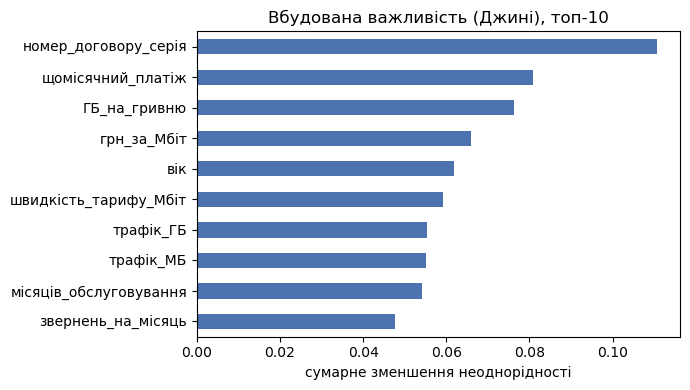

In [119]:
prep = model.named_steps['pre']
rf = model.named_steps['clf']
names_t = prep.get_feature_names_out()

cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']
def to_original(n):
    kind, rest = n.split('__', 1)
    if kind == 'cat':
        return max((c for c in cat_cols if rest.startswith(c + '_')), key=len)
    return rest

gini_imp = (pd.Series(rf.feature_importances_, index=names_t)
              .groupby(to_original).sum()
              .sort_values(ascending=False))

display(gini_imp.head(10).round(4).to_frame('вбудована важливість'))

ax = gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), color='#4C72B0')
ax.set_title('Вбудована важливість (Джині), топ-10')
ax.set_xlabel('сумарне зменшення неоднорідності')
plt.tight_layout(); plt.show()

Ми визначили, на які ознаки найбільше спиралася модель (випадковий ліс) під час навчання, коли розділяла клієнтів на тих, хто піде, і тих, хто залишиться, і вивели топ-10 таких ознак. Далі потрібно критично оцінити, чи справді ці ознаки пов'язані з відтоком клієнтів, чи модель лише знайшла в навчальних даних випадкові закономірності. Наприклад, на першому місці опинився `номер серії договору`, хоча змістовної причини впливати на рішення клієнта в нього немає.

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [120]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
місяців_обслуговування,0.026312
вік,0.024816
звернень_на_місяць,0.021031
швидкість_тарифу_Мбіт,0.020097
щомісячний_платіж,0.009972
трафік_МБ,0.009191
кількість_послуг,0.007715
кількість_звернень_у_підтримку,0.004013
тип_підключення,0.003525
місто,0.001202


Ми взяли навчену модель і перевірочні дані, по черзі перемішували значення кожної ознаки між клієнтами і дивилися, наскільки при цьому падає якість моделі (AUC). Якщо якість помітно падає, модель справді спирається на цю ознаку при прогнозі для нових клієнтів. Якщо майже не змінюється, модель може обійтися без цієї колонки (можливо). Як результат маємо: найважливіші `стаж обслуговування`, `вік`, `частота звернень` і `швидкість тарифу` (≈ 0.020–0.026 AUC кожна).

### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [121]:
cmp_imp = pd.DataFrame({
    'вбудована': gini_imp,
    'перестановочна': perm_imp,
    'ранг (вбудована)': gini_imp.rank(ascending=False).astype(int),
    'ранг (перестановочна)': perm_imp.rank(ascending=False).astype(int),
    'різних значень': FINAL_X.nunique(),
}).sort_values('вбудована', ascending=False)
display(cmp_imp.round(4))

ser = data['номер_договору_серія']
print('серій: %d, клієнтів у серії: від %d до %d (медіана %d)'
      % (ser.nunique(), ser.value_counts().min(), ser.value_counts().max(), ser.value_counts().median()))
print('частка відтоку по серіях: від %.2f до %.2f' % (y.groupby(ser).mean().min(), y.groupby(ser).mean().max()))

,вбудована,перестановочна,ранг (вбудована),ранг (перестановочна),різних значень
номер_договору_серія,0.1107,0.0011,1,12,55
щомісячний_платіж,0.0809,0.0100,2,5,1126
ГБ_на_гривню,0.0764,-0.0001,3,17,1090
грн_за_Мбіт,0.0659,-0.0002,4,18,1148
вік,0.0619,0.0248,5,2,63
швидкість_тарифу_Мбіт,0.0591,0.0201,6,4,9
трафік_ГБ,0.0554,0.0005,7,15,948
трафік_МБ,0.0550,0.0092,8,6,1200
місяців_обслуговування,0.0543,0.0263,9,1,87
звернень_на_місяць,0.0475,0.0210,10,3,136


серій: 55, клієнтів у серії: від 11 до 32 (медіана 21)
частка відтоку по серіях: від 0.00 до 0.50


`номер_договору_серія` — №1 за вбудованою важливістю (0.111), але лише №12 за перестановочною. Перемішування серії на перевірковій частині якості не змінює: модель нею насправді не користується для правильних прогнозів.

Чому вбудована її переоцінює: серія має 55 значень, після one-hot це 55 колонок, і в кожному дереві для кожної з них можна спробувати розбиття. У кожній серії лише 11–32 клієнти, а в таких маленьких групах частка тих, хто пішов, сильно коливається випадково — в одній серії не пішов ніхто, в іншій половина, — хоча сам номер серії ні на що не впливає.

На навчальних даних дерево завжди знаходить серію, у якій випадково майже ніхто не пішов, і виділяє її клієнтів в окрему групу. Вбудована важливість зараховує це серії як заслугу. Насправді це випадковість маленької групи, яка на нових клієнтах не повторюється. 

Та сама картина — у безперервних частках `ГБ_на_гривню` і `грн_за_Мбіт` (≈1100 різних значень, перестановочна ≈ 0).

In [122]:
FAKE_IMPORTANT = 'номер_договору_серія'
FAKE_IMPORTANT_WHY = ('№1 за вбудованою важливістю (0.111), але перестановочна ≈ 0; '
                      'серія має 55 значень (після one-hot — 55 колонок) і лише 11–32 клієнти в кожній, '
                      'тож частка відтоку між серіями випадково коливається від 0 до 0.5; дерево на навчальних даних '
                      'завжди знаходить серію, яка трохи «чистить» вузол, і вбудована важливість, порахована на навчальній '
                      'частині, записує цей шум як корисне розбиття')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: номер_договору_серія


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [123]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
display(pairs.head(6).round(4).to_frame('|r|'))
print('пари з |r| > 0.97:')
print(pairs[pairs > 0.97])

|r|
трафік_ГБ             трафік_МБ          0.9997
                      ГБ_на_гривню       0.8791
трафік_МБ             ГБ_на_гривню       0.8787
знижка_відсоток       є_знижка           0.8760
швидкість_тарифу_Мбіт щомісячний_платіж  0.7274
                      грн_за_Мбіт        0.6560

пари з |r| > 0.97:
трафік_ГБ  трафік_МБ    0.999685
dtype: float64


In [124]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

Xtr_d, Xte_d = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])
model_d = make_pipe(Xtr_d, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns)

print('\nбез %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_imp_d[DUP_PAIR[0]]))
print('   AUC на відкладеній частині: %.3f (з парою було %.3f)'
      % (roc_auc_score(yte, model_d.predict_proba(Xte_d)[:, 1]), auc_hold))

у повній моделі:
   трафік_ГБ                    +0.0005
   трафік_МБ                    +0.0092



без трафік_МБ:
   трафік_ГБ                    +0.0047
   AUC на відкладеній частині: 0.826 (з парою було 0.827)


In [125]:
DUP_EXPLANATION = 'трафік_ГБ і трафік_МБ — той самий трафік в різних одиницях; у повній моделі перестановочна важливість трафік_ГБ ≈ 0.0005, тобто «непотрібна»; після вилучення трафік_МБ і перенавчання вона зросла приблизно в 10 разів (≈ 0.005), а AUC майже не змінилась; поки обидві колонки в моделі, перемішування однієї нічого не ламає — дерева беруть ту саму інформацію з другої; перестановочна важливість точно відповідає на питання «що втратить модель без цієї колонки», і відповідь «майже нічого» правильна — хибним є висновок «отже ознака не важлива і її можна викинути»'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — той самий трафік в різних одиницях; у повній моделі перестановочна важливість трафік_ГБ ≈ 0.0005, тобто «непотрібна»; після вилучення трафік_МБ і перенавчання вона зросла приблизно в 10 разів (≈ 0.005), а AUC майже не змінилась; поки обидві колонки в моделі, перемішування однієї нічого не ламає — дерева беруть ту саму інформацію з другої; перестановочна важливість точно відповідає на питання «що втратить модель без цієї колонки», і відповідь «майже нічого» правильна — хибним є висновок «отже ознака не важлива і її можна викинути»


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

PDP для: ['місяців_обслуговування', 'вік', 'звернень_на_місяць']


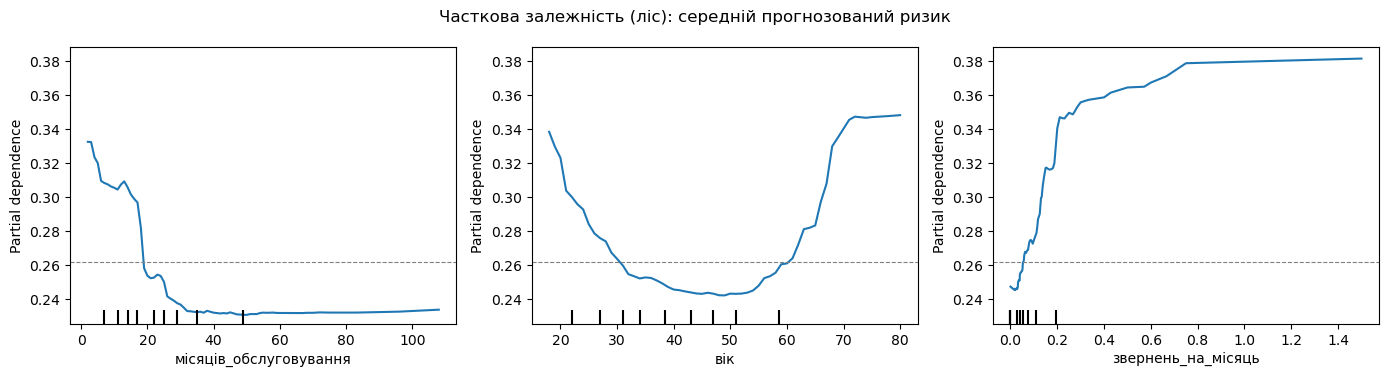

In [126]:
from sklearn.inspection import PartialDependenceDisplay

num_no_nan = [c for c in perm_imp.index
              if str(FINAL_X[c].dtype) != 'category' and FINAL_X[c].notna().all()]
TOP3 = num_no_nan[:3]
print('PDP для:', TOP3)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
PartialDependenceDisplay.from_estimator(model, Xte, features=TOP3, kind='average', ax=ax)
for a in np.ravel(fig.axes):
    a.axhline(y.mean(), ls='--', c='grey', lw=0.8)
fig.suptitle('Часткова залежність (ліс): середній прогнозований ризик')
plt.tight_layout(); plt.show()

- **Стаж обслуговування** — ризик спадає: у новачків (≈ 5 міс.) прогноз ≈ 0.32, після ≈ 2,5 років він стабілізується на ≈ 0.23. Найбільше ризикують перші два роки, далі клієнт «прив'язується».
- **Вік** — U-подібна крива: найвищий ризик у наймолодших (≈ 0.34 у 18 років), мінімум у віці ≈ 45–50 років (≈ 0.24), а після 55–60 ризик знову зростає.
- **Звернень на місяць** — ризик зростає з частотою звернень: від ≈ 0.25 у тих, хто не звертався, до ≈ 0.36 при одному зверненні кожні 3 місяці. Часті проблеми зі зв'язком штовхають до відходу.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

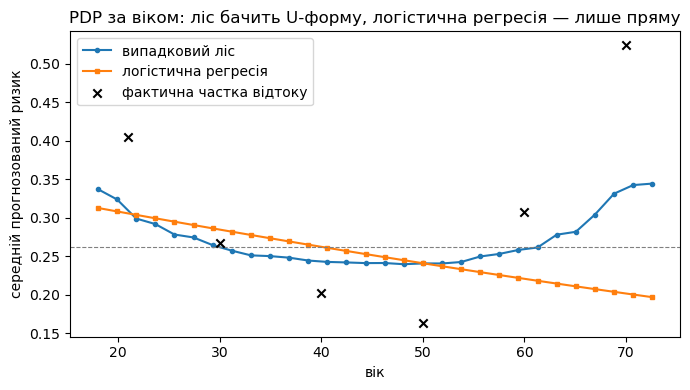

,частка відтоку (сирі дані)
вік,
"(17, 25]",0.405
"(25, 35]",0.267
"(35, 45]",0.202
"(45, 55]",0.163
"(55, 65]",0.307
"(65, 90]",0.524


In [127]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

pd_rf = partial_dependence(model,    FINAL_X, [NONLINEAR_FEATURE], kind='average',
                           grid_resolution=30, percentiles=(0.01, 0.99))
pd_lr = partial_dependence(lr_model, FINAL_X, [NONLINEAR_FEATURE], kind='average',
                           grid_resolution=30, percentiles=(0.01, 0.99))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pd_rf['grid_values'][0], pd_rf['average'][0], marker='o', ms=3, label='випадковий ліс')
ax.plot(pd_lr['grid_values'][0], pd_lr['average'][0], marker='s', ms=3, label='логістична регресія')
emp = y.groupby(pd.cut(FINAL_X[NONLINEAR_FEATURE], [17, 25, 35, 45, 55, 65, 90])).mean()
ax.scatter([21, 30, 40, 50, 60, 70], emp.values, c='k', marker='x', zorder=3, label='фактична частка відтоку')
ax.axhline(y.mean(), ls='--', c='grey', lw=0.8)
ax.set_xlabel('вік'); ax.set_ylabel('середній прогнозований ризик')
ax.set_title('PDP за віком: ліс бачить U-форму, логістична регресія — лише пряму')
ax.legend(); plt.tight_layout(); plt.show()

display(emp.round(3).to_frame('частка відтоку (сирі дані)'))

У лісу крива за віком має форму літери U. Сирі дані підтверджують це ще сильніше: відтік 0.41 у 18–25, 0.16 у 46–55 і 0.52 після 65. Логістична регресія за побудовою може провести лише пряму: її крива монотонно спадає (0.31 → 0.20) — для молодих вона приблизно права, а для літніх клієнтів помиляється в протилежний бік, називаючи найризиковішу групу найнадійнішою.

**Як допомогти логістичній регресії побачити нелінійність.** Логістична регресія рахує ризик як зважену суму ознак, тому від кожної ознаки ризик може залежати лише прямо: або зростати, або спадати. PDP лісу показав, що за віком залежність має форму літери U: ризик найнижчий близько 48 років і зростає в обидва боки.

Ризик залежить не від самого віку, а від того, наскільки вік віддалений від 48 років, — і від цієї відстані він зростає прямо. Тому додано ознаку (вік − 48)²: вона дорівнює нулю в 48 років і зростає на обох краях. Значення 48 взято з графіка PDP лісу — це точка мінімуму ризику.

In [128]:
NONLINEAR_MEANING = ('ризик відходу найвищий у молодих і в літніх клієнтів, а найнижчий — у віці ≈ 45–50 років')
NONLINEAR_FIX = ('додати ознаку (вік − 48)²')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик відходу найвищий у молодих і в літніх клієнтів, а найнижчий — у віці ≈ 45–50 років
додати ознаку (вік − 48)²


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [129]:
AGE_MIN = float(pd_rf['grid_values'][0][np.argmin(pd_rf['average'][0])])
print('мінімум ризику за PDP: вік ≈ %.0f' % AGE_MIN)

X6 = X5.copy()
X6['вік_відхилення_кв'] = (X6['вік'] - AGE_MIN) ** 2

auc6 = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc5, auc6)
print('логістична без ознаки: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (auc6.mean(), auc6.std()))
print('приріст: %+.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику за PDP: вік ≈ 48
логістична без ознаки: AUC 0.813 ± 0.027
логістична з ознакою : AUC 0.839 ± 0.025
приріст: +0.0259 ± 0.0067   значуще


In [130]:
QUAD_GAIN = float(m_q)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0259


Одна ознака (вік − 48)², підказана графіком, дала логістичній регресії **+0.026 ± 0.007** AUC (0.813 → 0.839) — значущий приріст. Для порівняння: чотири ознаки «з голови» в розділі 8 дали −0.001, а випадковий ліс замість логістичної регресії — +0.003 (у межах шуму). Тепер логістична регресія з цією ознакою (0.839) обходить ліс (0.817), лишаючись повністю прозорою.

### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

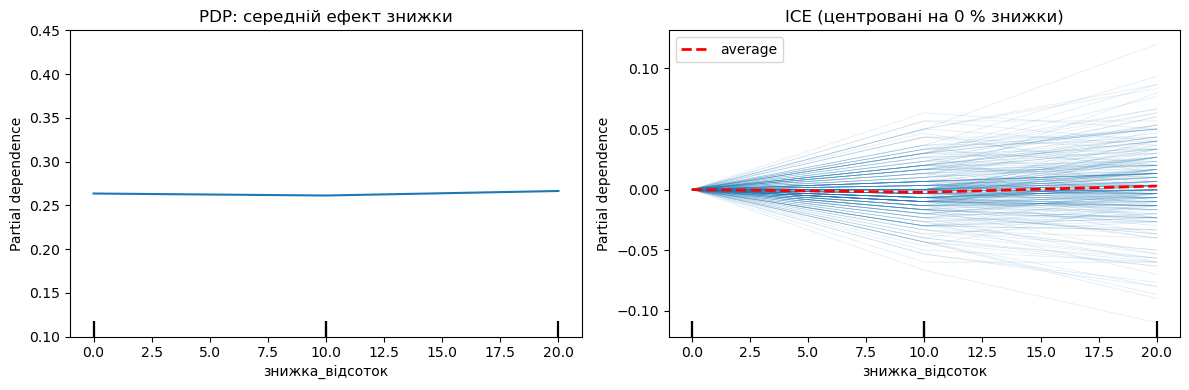

ICE: ризик зі знижкою росте у 51% клієнтів, падає у 42%


In [131]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

d0 = PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
d0.axes_[0][0].set_ylim(0.1, 0.45)
d0.axes_[0][0].set_title('PDP: середній ефект знижки')


PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='both',
                                        subsample=300, random_state=SEED, centered=True, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.15}, pd_line_kw={'color': 'red', 'lw': 2})
ax[1].set_title('ICE (центровані на 0 % знижки)')
plt.tight_layout(); plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
delta = ice[:, -1] - ice[:, 0]
print('ICE: ризик зі знижкою росте у %.0f%% клієнтів, падає у %.0f%%'
      % ((delta > 0).mean() * 100, (delta < 0).mean() * 100))

ICE показує, що клієнти реагують по-різному, але не хто саме.

стаж < 24 міс   прогноз при знижці 0/10/20 %: [0.309 0.313 0.321]
стаж ≥ 24 міс   прогноз при знижці 0/10/20 %: [0.205 0.194 0.195]


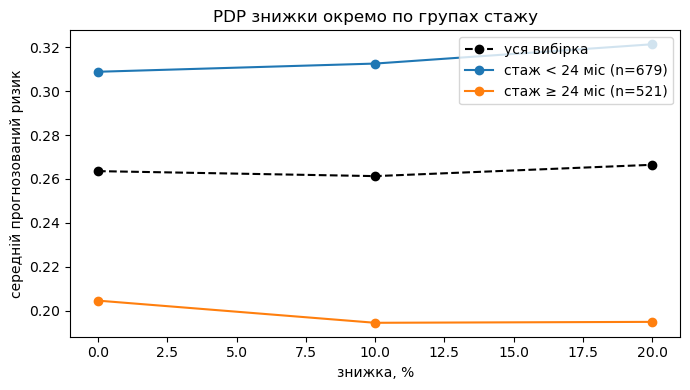

In [132]:
TENURE_CUT = 24
groups = {'стаж < 24 міс':  FINAL_X['місяців_обслуговування'] < TENURE_CUT,
          'стаж ≥ 24 міс':  FINAL_X['місяців_обслуговування'] >= TENURE_CUT}

fig, ax = plt.subplots(figsize=(7, 4))
pd_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ax.plot(pd_all['grid_values'][0], pd_all['average'][0], 'k--', marker='o', label='уся вибірка')
for name, mask in groups.items():
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (name, mask.sum()))
    print('%-15s прогноз при знижці 0/10/20 %%: %s' % (name, np.round(r['average'][0], 3)))
ax.set_xlabel('знижка, %'); ax.set_ylabel('середній прогнозований ризик')
ax.set_title('PDP знижки окремо по групах стажу')
ax.legend(); plt.tight_layout(); plt.show()

Загальний PDP знижки майже плаский: якщо вірити лише йому, знижка ні на що не впливає. 

ICE-криві показують інше — вони йдуть у різні боки: приблизно в половини клієнтів знижка підвищує прогноз, у решти знижує. 

PDP по групах це розділяє: у клієнтів зі стажем < 24 міс прогноз зі знижкою **росте**, у клієнтів зі стажем ≥ 24 міс — **падає**.

Загальне спостереження: серед нових клієнтів ті, хто має велику знижку, йдуть частіше, а серед давніх клієнтів — навпаки, рідше. Це не доведена причина, а лише зв'язок, помітний у цих даних.

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [133]:
tenure_grp = pd.Series(np.where(FINAL_X['місяців_обслуговування'] < TENURE_CUT, 'стаж < 24 міс', 'стаж ≥ 24 міс'),
                       index=FINAL_X.index, name='група стажу')
emp_rate = pd.crosstab(tenure_grp, FINAL_X['знижка_відсоток'], values=y, aggfunc='mean').round(3)
emp_n    = pd.crosstab(tenure_grp, FINAL_X['знижка_відсоток'])
print('частка відтоку (сирі дані):'); display(emp_rate)
print('розмір груп:');                 display(emp_n)

model_rate = pd.DataFrame({name: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'],
                                                    kind='average')['average'][0]
                           for name, mask in groups.items()}, index=[0, 10, 20]).T.round(3)
print('прогноз моделі (PDP по групах):'); display(model_rate)

частка відтоку (сирі дані):


знижка_відсоток,0.0,10.0,20.0
група стажу,,,
стаж < 24 міс,0.292,0.347,0.397
стаж ≥ 24 міс,0.241,0.124,0.094


розмір груп:


знижка_відсоток,0.0,10.0,20.0
група стажу,,,
стаж < 24 міс,264,236,179
стаж ≥ 24 міс,203,169,149


прогноз моделі (PDP по групах):


,0,10,20
стаж < 24 міс,0.309,0.313,0.321
стаж ≥ 24 міс,0.205,0.194,0.195


Сирі дані показують сильну взаємодію: у клієнтів зі стажем ≥ 24 міс відтік падає зі знижкою, а в клієнтів зі стажем < 24 міс **росте**.

PDP по групах: напрям збігається, бо у новачків зі знижкою відтік росте, у давніх клієнтів зі знижкою відтік падає.

Модель відтворює напрям ефекту, але приглушує його в 9–15 разів: у новачків при переході від 0 % до 20 % знижки частка відтоку в даних зростає на 0.105, а прогноз моделі — лише на 0.012; у давніх клієнтів у даних вона падає на 0.147, а в моделі — лише на 0.010.

In [134]:
INTERACTION_FOUND = ('серед нових клієнтів ті, хто має велику знижку, йдуть частіше, а серед давніх клієнтів — навпаки, рідше')
BUSINESS_ACTION = ('не використовувати знижку як універсальний засіб утримання. Варто шукати інші підходи.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

серед нових клієнтів ті, хто має велику знижку, йдуть частіше, а серед давніх клієнтів — навпаки, рідше
не використовувати знижку як універсальний засіб утримання. Варто шукати інші підходи.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [135]:
import shap

prep = model.named_steps['pre']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 97)


У нашому конвеєрі крок перетворення називається `'pre'` (див. `make_pipe`), тому тут `named_steps['pre']` замість `'prep'` із шаблону. Матриця: 300 клієнтів × 97 колонок після one-hot.

### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

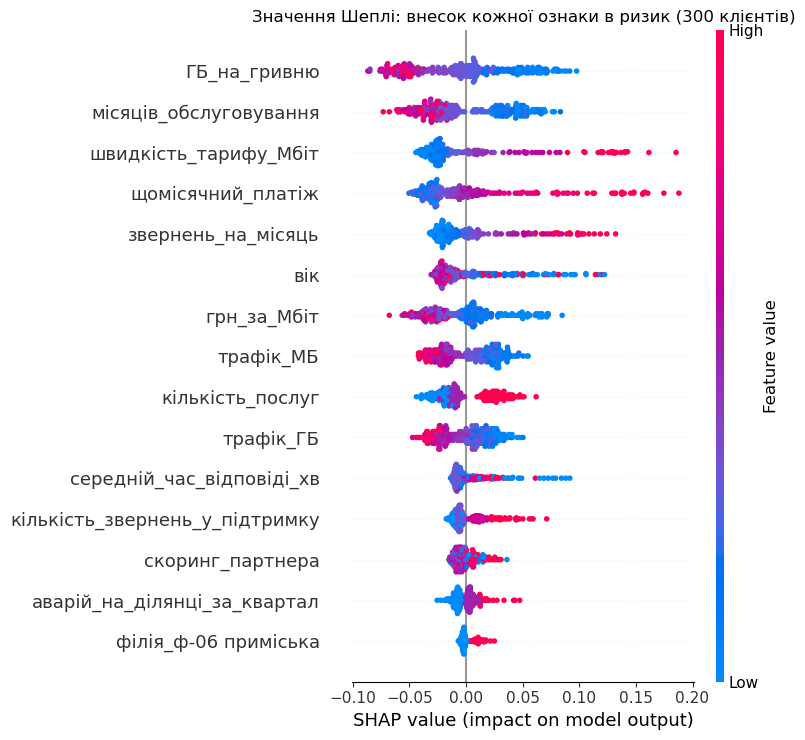

,середній |внесок|,кореляція значення з внеском
ГБ_на_гривню,0.0375,-0.86
місяців_обслуговування,0.0333,-0.76
швидкість_тарифу_Мбіт,0.0331,0.96
щомісячний_платіж,0.0321,0.90
звернень_на_місяць,0.0241,0.78
вік,0.0239,-0.34
грн_за_Мбіт,0.0230,-0.74
трафік_МБ,0.0228,-0.88
кількість_послуг,0.0209,0.90
трафік_ГБ,0.0185,-0.88


In [136]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=[n.split('__', 1)[1] for n in feat_names],
                  max_display=15, show=False)
plt.title('Значення Шеплі: внесок кожної ознаки в ризик (300 клієнтів)')
plt.tight_layout(); plt.show()

num_idx = [k for k, n in enumerate(feat_names) if n.startswith('num__')]
direction = pd.Series({feat_names[k].split('__', 1)[1]:
                       np.corrcoef(Xte_t[:SAMPLE, k], sv1[:, k])[0, 1] for k in num_idx})
mean_abs = pd.Series(np.abs(sv1).mean(0), index=feat_names)
top_num = mean_abs[[feat_names[k] for k in num_idx]].sort_values(ascending=False).head(10)
display(pd.DataFrame({'середній |внесок|': top_num.values.round(4),
                      'кореляція значення з внеском': direction[[n.split('__', 1)[1] for n in top_num.index]].values.round(2)},
                     index=[n.split('__', 1)[1] for n in top_num.index]))

**Як читати цей графік**
- Кожен рядок — одна ознака, зверху найважливіші.
- Кожна точка — один клієнт.
- Колір — значення ознаки в цього клієнта: червоний означає велике, синій — мале.
- Позиція по горизонталі (SHAP value) — на скільки ця ознака змінила ризик цього клієнта: праворуч — підвищила, ліворуч — знизила.
- Розкид точок у рядку — наскільки сильно ознака впливає: що ширше розкидані точки, то сильніший вплив.

Що дає beeswarm:
- Висока швидкість тарифу, високий платіж і часті звернення (червоні точки) лежать праворуч — підвищують ризик. Великий стаж (червоні) лежить ліворуч — знижує ризик. Більше гігабайтів на гривню (червоні) — ліворуч: хто активно користується інтернетом, той рідше йде.

- Для стажу, швидкості й платежу кольори чітко розділені — напрям однаковий для всіх клієнтів. Для `віку` червоні і сині точки є по обидва боки від нуля: і молоді, і найстарші отримують додатний внесок.

Для більшості важливих ознак кореляція між значенням ознаки і її внеском висока за модулем (0.75–0.96): ознака діє на всіх клієнтів в одному напрямку. Для віку вона слабка (−0.34). Кореляція вимірює лише прямолінійний зв'язок, а у розділі 10.2 видно що у нас нелінійність є (U-подібний графік).

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [137]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

base_value = float(np.ravel(expl.expected_value)[-1])
contrib = pd.Series(sv1[idx], index=[n.split('__', 1)[1] for n in feat_names])
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)

client = Xte.iloc[idx]
print('базовий рівень (середній ризик): %.3f; сума внесків: %+.3f; разом: %.3f'
      % (base_value, contrib.sum(), base_value + contrib.sum()))
print('чи справді пішов: %s\n' % ('так' if yte.iloc[idx] == 1 else 'ні'))
print('три найбільші внески:')
for f, v in top3.items():
    print('   %-26s значення: %-10s внесок: %+.3f' % (f, round(client[f], 3), v))

print('\nдля порівняння, медіани по всіх клієнтах:')
display(FINAL_X[top3.index.tolist() + ['місяців_обслуговування', 'трафік_ГБ']].median().round(2).to_frame('медіана'))

ризик клієнта: 0.873
базовий рівень (середній ризик): 0.262; сума внесків: +0.611; разом: 0.873
чи справді пішов: так

три найбільші внески:
   швидкість_тарифу_Мбіт      значення: 1000.0     внесок: +0.137
   щомісячний_платіж          значення: 496.1      внесок: +0.132
   ГБ_на_гривню               значення: 0.23       внесок: +0.078

для порівняння, медіани по всіх клієнтах:


,медіана
швидкість_тарифу_Мбіт,200.00
щомісячний_платіж,307.00
ГБ_на_гривню,0.56
місяців_обслуговування,21.00
трафік_ГБ,168.60


Клієнтка користується тарифом — 1000 Мбіт/с, за який платить близько 500 грн на місяць, тоді як типовий абонент платить близько 300 грн за 200 Мбіт/с. При цьому інтернетом вона користується мало: за кожну гривню отримує приблизно удвічі менше трафіку, ніж типовий абонент. Імовірно, вона вважає, що переплачує за швидкість, яка їй не потрібна. Розмову варто почати з того, чи влаштовує її тариф, і запропонувати дешевший варіант з меншою швидкістю

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [138]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'
SHAP_NOT_CAUSAL_WHY = 'Для ознаки звернень_на_місяць значення Шеплі додатні і зростають, чим частіше клієнт звертається в підтримку. Якщо прочитати це як причину, виходить хибний висновок: щоб утримати клієнтів, треба зменшити кількість звернень. Насправді звернення — симптом: клієнт звертається, коли в нього проблеми зі зв\'язком, і ті самі проблеми штовхають його піти. Діяти треба на причину: покращувати якість лінії, зменшувати кількість аварій, прискорювати відповіді підтримки. Вплив цих дій потрібно перевіряти експериментом.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

звернень_на_місяць — Для ознаки звернень_на_місяць значення Шеплі додатні і зростають, чим частіше клієнт звертається в підтримку. Якщо прочитати це як причину, виходить хибний висновок: щоб утримати клієнтів, треба зменшити кількість звернень. Насправді звернення — симптом: клієнт звертається, коли в нього проблеми зі зв'язком, і ті самі проблеми штовхають його піти. Діяти треба на причину: покращувати якість лінії, зменшувати кількість аварій, прискорювати відповіді підтримки. Вплив цих дій потрібно перевіряти експериментом.


---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [139]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",звернень_на_місяць,"питання, чи можна на цю ознаку вплинути взагалі"


Кожен інструмент пояснення відповідає на своє вузьке питання, і кожна з чотирьох помилок — це спроба прочитати відповідь як відповідь на інше питання: «дерево часто ріже» ≠ «ознака допомагає на нових даних»; «без цієї колонки нічого не втрачено» ≠ «ця інформація не потрібна»; «середній ефект нуль» ≠ «ефекту немає»; «модель користується» ≠ «зміна допоможе».

### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [140]:
after_break = pd.to_datetime(data['дата_підключення']) >= BREAK_DATE
high_speed = data['швидкість_тарифу_Мбіт'] >= 400

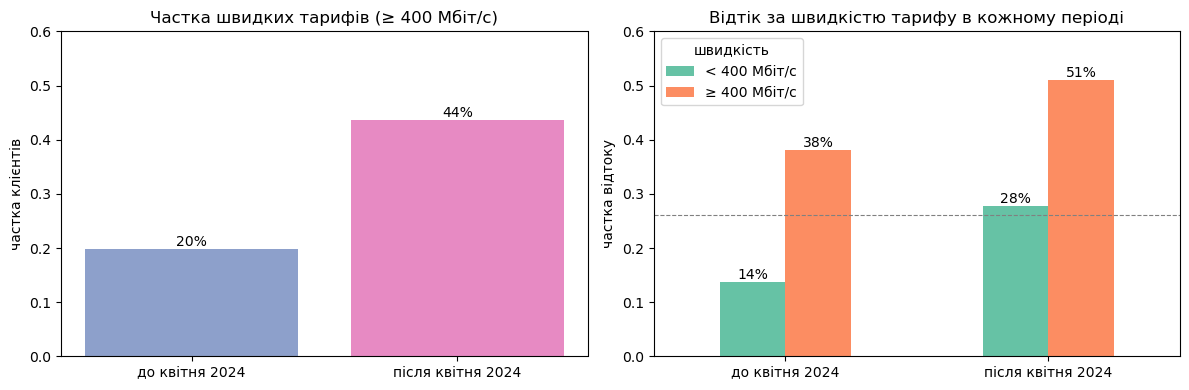

In [141]:
after_break = pd.to_datetime(data['дата_підключення']) >= BREAK_DATE
high_speed = data['швидкість_тарифу_Мбіт'] >= 400


period = after_break.map({False: 'до квітня 2024', True: 'після квітня 2024'})
speed  = high_speed.map({False: '< 400 Мбіт/с', True: '≥ 400 Мбіт/с'})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))


share = high_speed.groupby(period).mean()
bars = ax[0].bar(share.index, share.values, color=['#8DA0CB', '#E78AC3'])
ax[0].bar_label(bars, labels=['%.0f%%' % (v * 100) for v in share.values])
ax[0].set_ylim(0, 0.6); ax[0].set_ylabel('частка клієнтів')
ax[0].set_title('Частка швидких тарифів (≥ 400 Мбіт/с)')


rate = y.groupby([period, speed]).mean().unstack()
rate.plot.bar(ax=ax[1], color=['#66C2A5', '#FC8D62'], rot=0)
for c in ax[1].containers:
    ax[1].bar_label(c, labels=['%.0f%%' % (v * 100) for v in c.datavalues])
ax[1].axhline(y.mean(), ls='--', c='grey', lw=0.8)
ax[1].set_ylim(0, 0.6); ax[1].set_xlabel(''); ax[1].set_ylabel('частка відтоку')
ax[1].set_title('Відтік за швидкістю тарифу в кожному періоді')
ax[1].legend(title='швидкість')

plt.tight_layout(); plt.show()

Ліва діаграма. Ті, хто підключився після квітня 2024, удвічі частіше беруть швидкі тарифи.

Права діаграма. Хто має швидкий тариф, той іде частіше, і це видно як до квітня 2024, так і після.

Але після квітня 2024 відтік записаний вищим для всіх, бо змінився облік. А швидких тарифів якраз більше серед цих «нових» клієнтів.

Висновок: модель вважає швидкість ще важливішою, ніж вона є насправді, бо разом зі справжнім впливом швидкості «підхоплює» і помилку обліку.

---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

у перевірковій частині: 360 клієнтів, з них пішли 94 (26.1%)
топ-100 за ризиком     : пішли 60 (60%)
випадкові 100          : пішли б у середньому ≈ 26
lift = 2.30
частка всіх, хто пішов, яку покриває список: 64%


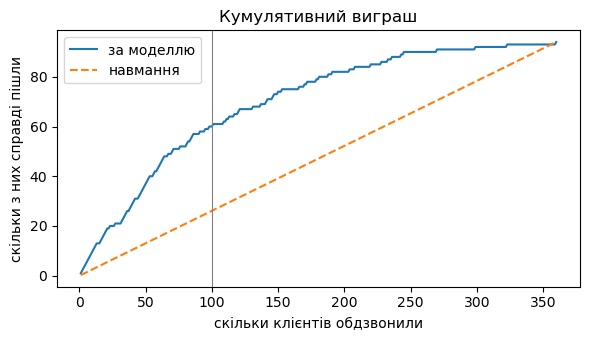

In [142]:
TOP_N = 100
risk_te = model.predict_proba(Xte)[:, 1]
order = np.argsort(-risk_te)
top = yte.iloc[order[:TOP_N]]

found_top    = int(top.sum())
rate_top     = top.mean()
rate_all     = yte.mean()
found_random = rate_all * TOP_N
lift = rate_top / rate_all

print('у перевірковій частині: %d клієнтів, з них пішли %d (%.1f%%)' % (len(yte), yte.sum(), rate_all * 100))
print('топ-%d за ризиком     : пішли %d (%.0f%%)' % (TOP_N, found_top, rate_top * 100))
print('випадкові %d          : пішли б у середньому ≈ %.0f' % (TOP_N, found_random))
print('lift = %.2f' % lift)
print('частка всіх, хто пішов, яку покриває список: %.0f%%' % (found_top / yte.sum() * 100))

k = np.arange(1, len(yte) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(k, yte.iloc[order].cumsum().values, label='за моделлю')
plt.plot(k, k * rate_all, '--', label='навмання')
plt.axvline(TOP_N, c='grey', lw=0.8)
plt.xlabel('скільки клієнтів обдзвонили'); plt.ylabel('скільки з них справді пішли')
plt.legend(); plt.title('Кумулятивний виграш'); plt.tight_layout(); plt.show()

In [143]:
LIFT_MEANING = 'Якщо дзвонити 100 клієнтам зі списку моделі, серед них буде 60 тих, хто справді збирається піти, а якщо дзвонити 100 випадковим, то лише 26.'
assert LIFT_MEANING
print(LIFT_MEANING)

Якщо дзвонити 100 клієнтам зі списку моделі, серед них буде 60 тих, хто справді збирається піти, а якщо дзвонити 100 випадковим, то лише 26.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [144]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_15.json


Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

**Відповіді**

1. Обрано AUC. У даних 886 клієнтів лишились і 314 пішли, тож accuracy буде давати завищені оцінки через дизбаланс класів.
Повнота (recall) не карає за хибні тривоги (модель «усі підуть» має повноту 1.0), 
F1 залежить від порогу, який визначає бізнес. 
AUC не залежить ні від порогу, ні від дисбалансу і показує, чи ставить модель ризикових клієнтів вище за лояльних — саме так працюватиме відділ утримання, обдзвонюючи список згори вниз.

2. 
| стовпець | коли з'являється | чому вилучено |
|---|---|---|
| `id_клієнта` | при підключенні | ідентифікатор: нічого не пояснює, модель лише запам'ятовує клієнтів |
| `дата_розірвання` | після розірвання договору | у момент прогнозу договір чинний |
| `сума_повернення_депозиту` | після розірвання договору | депозит повертають лише після відходу |
| `кількість_дзвінків_утримання` | після того, як клієнт заявив про намір піти | відділ утримання дзвонить тим, хто вже вирішив піти |
| `дата_підключення` | при підключенні | стрибок відтоку з 2024Q2 одночасно в усіх філіях; модель хибно вважатиме пізно підключених клієнтів в зоні ризику |

Детектор із 5.1 не знайшов `кількість_дзвінків_утримання`: колонка заповнена в усіх клієнтів (де дзвінків не було, стоїть 0, а не пропуск), а детектор перевіряє лише факт заповненості. Витік ховається у значенні, а не в наявності значення.

3. AUC **0.814 ± 0.027** (стандартне відхилення по 20 згортках стратифікованої 5-кратної перевірки з 4 повторами). Розкид між згортками (0.027) майже в 7 разів більший за різницю 0.004, тож за різницею середніх дві такі моделі не розрізнити. Потрібне парне порівняння на тих самих згортках.

4. Так, він пов'язаний з датою підключення: ті самі чесні ознаки передбачають, чи підключився клієнт після 2024-04-01, з **AUC 0.790**. Після вилучення дати AUC відтоку впала з 0.831 до 0.814. Філія артефактом не є: її ознаки не видають (**AUC 0.492**), а частка відтоку між філіями змінюється плавно (0.24–0.30). Тому переносити модель в іншу філію загалом можна — вона не вивчила особливостей конкретної філії.

5. **Нові ознаки чи складніша модель.** Жоден шлях не дав значущого приросту. Чотири нові ознаки (розділ 8) дали логістичній регресії −0.0011 ± 0.0017, випадковий ліс замість логістичної регресії — +0.0026 ± 0.0095, гістограмний бустинг — −0.0044 ± 0.0103: усі довірчі інтервали накривають нуль. За ціною нові ознаки майже безкоштовні (логістична регресія ≈ 1.8 с на 20 навчань), а складніша модель коштує у 8–11 разів більше (14.8–19.7 с) без виграшу в якості. Кожна нова ознака є відношенням двох колонок, які модель уже бачить, тому нової інформації вони не додали.

   Натомість одна ознака, підказана інтерпретацією моделі, — (вік − 48)² у розділі 10.2б — дала логістичній регресії **+0.026 ± 0.007** (0.813 → 0.839). Це більше, ніж дали і ознаки «з голови», і складніша модель.

6. **Хибно важлива ознака — `номер_договору_серія`.** Вона №1 за вбудованою важливістю (0.111), але лише №12 за перестановочною (0.001, тобто фактично нуль). Серія має 55 значень (після one-hot — 55 колонок), і в кожній лише 11–32 клієнти. У таких маленьких групах частка тих, хто пішов, сильно коливається випадково — в одній серії не пішов ніхто, в іншій половина, — хоча сам номер серії ні на що не впливає.

   Дерева так роблять, бо обирають розбиття, яке найкраще зменшує неоднорідність на **навчальних** даних. Ознака з багатьма значеннями дає багато можливих розбиттів, і серед них завжди знайдеться таке, що випадково «чистить» групу. Вбудована важливість рахується на тих самих навчальних даних і зараховує цей шум як заслугу ознаки. На нових клієнтах ця випадковість не повторюється, і перестановочна важливість це показує.

7. **Дубльована пара — `трафік_ГБ` і `трафік_МБ`** (той самий трафік у різних одиницях, |r| = 0.9997). У повній моделі перестановочна важливість `трафік_ГБ` ≈ 0.0005, тобто ознака виглядає непотрібною. Після вилучення `трафік_МБ` і перенавчання вона зросла приблизно в 10 разів (≈ 0.0047), а AUC майже не змінилась (0.827 → 0.826). Поки обидві колонки в моделі, перемішування однієї нічого не ламає — модель бере ту саму інформацію з другої.

   Це не вада методу: перестановочна важливість точно відповідає на питання «що втратить модель без цієї колонки», і відповідь «майже нічого» правильна. Хибним є висновок «важливість нуль, отже ознаку можна викинути» — якби ми викинули обидві колонки, модель втратила б інформацію про трафік.

8. **Немонотонний вплив має `вік`.** PDP лісу має форму літери U: ризик ≈ 0.34 у 18 років, мінімум ≈ 0.24 близько 48 років і знову зростання після 60. Сирі дані підтверджують це ще сильніше: відтік 0.41 у 18–25 років, 0.16 у 46–55 і 0.52 після 65. Логістична регресія без втручання цього не побачила б: вона рахує ризик як зважену суму ознак, тому від віку він може лише зростати або лише спадати. Її крива монотонно спадає (0.31 → 0.20) і для літніх клієнтів помиляється в протилежний бік. Після додавання ознаки (вік − 48)² її AUC зросла на 0.026 ± 0.007.

9. **PDP збрехав для `знижка_відсоток`.** Загальний PDP майже пласкатий (0.264 → 0.261 → 0.266): якщо вірити лише йому, знижка ні на що не впливає. ICE-криві розходяться віялом: у 51 % клієнтів прогноз зі знижкою росте, у 42 % — падає. PDP по групах стажу показав, хто саме: серед нових клієнтів (стаж < 24 міс) ті, хто має знижку, йдуть частіше, а серед давніх — рідше. Сирі дані це підтверджують: у новачків відтік зростає з 0.292 до 0.397, у давніх клієнтів падає з 0.241 до 0.094. Протилежні ефекти в середньому гасяться, тому загальна крива пласка. Ліс відтворює напрям ефекту, але приглушує його в 9–15 разів.

10. **Великий внесок за Шеплі без причинності — `звернень_на_місяць`.** Її значення Шеплі додатні і зростають, чим частіше клієнт звертається в підтримку (5-та за середнім внеском, +0.07 у найризиковішої клієнтки). Якщо прочитати це як причину, виходить хибний висновок: щоб утримати клієнтів, треба зменшити кількість звернень. Насправді звернення — симптом: клієнт звертається, коли в нього проблеми зі зв'язком, і ті самі проблеми штовхають його піти. Якщо обмежити звернення, проблеми лишаться, а клієнт стане ще незадоволенішим.

    «Модель цим користується» означає, що ознака допомагає **вгадати**, хто піде. «Це причина» означає, що **зміна** ознаки змінить результат. Значення Шеплі показують лише перше. Для другого потрібен причинний висновок, якого в даних немає, тому ефект будь-яких дій треба перевіряти експериментом.

11. **Що сказати замовникові.** Якщо обдзвонити 100 клієнтів зі списку моделі, серед них буде 60 тих, хто справді збирається піти, а серед 100 випадкових — лише ≈ 26. **Lift = 2.30**, загальна якість моделі — AUC 0.814 ± 0.027.

    Застереження: модель **знаходить** тих, хто збирається піти, але не доводить, що дзвінок їх утримає.

### Декларація про використання штучного інтелекту

Залучала ШІ-агента для роз'яснення термінології, аналітики даних та написання коду.

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.